Ujian Tengah Semester (UTS) - Graf Sains Data
Nama: Sandi Ardi Prayitno
NIM: 24031554037
Mata Kuliah: Graf Sains Data 

## 1. koneksi ke data base

In [1]:
from neo4j import GraphDatabase, RoutingControl

# Sesuaikan URI dan Password database Neo4j Anda
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "ardi12345")  # Ganti "password" sesuai password akun Neo4j Anda

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j"
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ
    )
    for record in records:
        print(f"Teman {name}: {record['friend.name']}")

# Jalankan tes koneksi
try:
    with GraphDatabase.driver(URI, auth=AUTH) as driver:
        add_friend(driver, "Arthur", "Guinevere")
        add_friend(driver, "Arthur", "Lancelot")
        add_friend(driver, "Arthur", "Merlin")
        print_friends(driver, "Arthur")
    print("\nKoneksi ke Neo4j Berhasil!")
except Exception as e:
    print(f"\nGagal terhubung ke Neo4j: {e}")

Teman Arthur: Guinevere
Teman Arthur: Lancelot
Teman Arthur: Merlin

Koneksi ke Neo4j Berhasil!


## SOAL

**1. Nama database pada tutorial?**  
`neo4j` (database bawaan; terlihat pada argumen `database_="neo4j"`). Selain itu ada database `system`
yang menyimpan metadata/manajemen.

**2. Akses lain untuk database lain dalam satu instance?**
- **Klausa Cypher `USE <nama_db>`** di awal query, mis. `USE tokoonline MATCH (n) RETURN count(n)`.
- **Parameter driver:** `database_="nama_db"` pada `execute_query`, atau `driver.session(database="nama_db")`.
- **Neo4j Browser / `cypher-shell`:** perintah `:use nama_db`.
- DDL manajemen database dijalankan dari database `system`: `CREATE DATABASE nama_db`, `SHOW DATABASES`, `DROP DATABASE nama_db`.
- *Catatan:* **Community Edition** hanya mengizinkan satu database pengguna (`neo4j`) + `system`;
  banyak database dalam satu instance memerlukan **Enterprise Edition**.

**3. Jenis graf pertemanan yang dibuat?**  
Graf **berarah** (`(a)-[:KNOWS]->(friend)`), **tak berbobot**, **homogen** (satu label `Person`, satu tipe relasi `KNOWS`),
berbentuk **graf bintang (*star*)** dengan Arthur sebagai hub (derajat keluar 3, tidak ada siklus).
Secara model data, ia disimpan sebagai *labeled property graph*.
Karena `KNOWS` berarah, Arthur "mengenal" ketiganya tetapi belum tentu sebaliknya (tidak simetris).

## 2. pembersihan data base

In [2]:
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "ardi12345" 

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))

with driver.session(database="neo4j") as session:
    print("Memulai pembersihan database secara bertahap...")
    total_deleted = 0
    while True:
        # Hapus 5.000 node beserta relasinya per transaksi
        result = session.run("MATCH (n) WITH n LIMIT 5000 DETACH DELETE n RETURN count(n) AS count")
        count = result.single()["count"]
        total_deleted += count
        if count == 0:
            break
        print(f"Terhapus {count:,} node (Total akumulasi: {total_deleted:,})...")

driver.close()
print(f" Database neo4j berhasil dibersihkan sepenuhnya! Total node dihapus: {total_deleted:,}")

Memulai pembersihan database secara bertahap...
Terhapus 4 node (Total akumulasi: 4)...
 Database neo4j berhasil dibersihkan sepenuhnya! Total node dihapus: 4


## 3. Melakukan filter dataset

In [3]:
import pandas as pd

# 1. Baca dataset utama
df = pd.read_csv(r"C:\Users\sandi\Downloads\UTS_Graf\data\events.csv")

# 2. Konversi timestamp (ms) ke bentuk datetime
df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

# 3. Tentukan rentang Opsi 3 (15 Hari)
# P1 (Training): 1 - 8 September 2015
# P2 (Testing) : 9 - 15 September 2015
p1_start, p1_end = '2015-09-01 00:00:00', '2015-09-08 23:59:59'
p2_start, p2_end = '2015-09-09 00:00:00', '2015-09-15 23:59:59'

df_p1 = df[(df['datetime'] >= p1_start) & (df['datetime'] <= p1_end)]
df_p2 = df[(df['datetime'] >= p2_start) & (df['datetime'] <= p2_end)]

# 4. Gabungkan dan simpan ke file CSV
df_filtered = pd.concat([df_p1, df_p2]).drop(columns=['datetime'])
df_filtered.to_csv('events_filtered.csv', index=False)

print("--- PEMFILTERAN BERHASIL (OPSI 3) ---")
print(f"Data P1 (1 - 8 Sept 2015)   : {len(df_p1):,} baris")
print(f"Data P2 (9 - 15 Sept 2015)  : {len(df_p2):,} baris")
print(f"Total data events_filtered  : {len(df_filtered):,} baris")

# [TAMBAHAN] simpan juga per-fold. Graf Neo4j hanya dibangun dari P1 (training),
# sedangkan P2 (testing) dipakai sebagai ground truth saja -> tidak ada kebocoran data.
df_p1.drop(columns=['datetime']).to_csv('events_p1.csv', index=False)
df_p2.drop(columns=['datetime']).to_csv('events_p2.csv', index=False)
print("Tersimpan: events_filtered.csv, events_p1.csv, events_p2.csv")

--- PEMFILTERAN BERHASIL (OPSI 3) ---
Data P1 (1 - 8 Sept 2015)   : 141,038 baris
Data P2 (9 - 15 Sept 2015)  : 139,521 baris
Total data events_filtered  : 280,559 baris
Tersimpan: events_filtered.csv, events_p1.csv, events_p2.csv


## 4. Impor Batch Data ke Neo4j

In [4]:
import pandas as pd   
import os
from neo4j import GraphDatabase
from tqdm import tqdm

URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "ardi12345"
csv_file_path = "events_p1.csv"   
def create_constraints(session):
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE;")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE;")

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

# Menggunakan batch_size = 1000 agar alokasi memori Neo4j tetap aman
batch_size = 1000

with open(csv_file_path, 'r', encoding='utf-8') as f:
    total_rows = sum(1 for _ in f) - 1

total_chunks = (total_rows // batch_size) + 1

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD), notifications_min_severity="OFF")  # [REVISI] sembunyikan peringatan deprecation
with driver.session(database="neo4j") as session:
    create_constraints(session)
    print("Memulai proses impor batch data ke Neo4j...")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Data"):
        chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor batch berhasil!")

Memulai proses impor batch data ke Neo4j...


Mengimpor Data: 100%|██████████| 142/142 [00:20<00:00,  6.98it/s]

Proses impor batch berhasil!


## Verifikasi

In [ ]:
EVENT2REL = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "BOUGHT"}
expected = df_p1["event"].map(EVENT2REL).value_counts()

with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as drv:
    rows, _, _ = drv.execute_query(
        "MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->() RETURN type(r) AS rel, count(r) AS n",
        database_="neo4j")
got = {r["rel"]: r["n"] for r in rows}

cek = pd.DataFrame({"CSV P1": expected, "Neo4j": pd.Series(got)}).fillna(0).astype(int)
cek["cocok"] = cek["CSV P1"] == cek["Neo4j"]
print(cek)
assert cek["cocok"].all(), "Jumlah relasi tidak cocok -> jalankan sel pembersihan database, lalu impor ulang SEKALI saja"
print("Graf konsisten dengan CSV P1.")

               CSV P1   Neo4j  cocok
VIEWED         136420  136420   True
ADDED_TO_CART    3532    3532   True
BOUGHT           1086    1086   True
OK: graf konsisten dengan CSV P1.


## 5. Query untuk mendapatkan komposisi dari subgraph 

In [6]:
with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    # 1. Menghitung jumlah simpul per label
    node_records, _, _ = driver.execute_query(
        "MATCH (n) RETURN labels(n)[0] AS Label, count(n) AS JumlahNode",
        database_="neo4j"
    )
    
    # 2. Menghitung jumlah relasi per tipe
    rel_records, _, _ = driver.execute_query(
        "MATCH ()-[r]->() RETURN type(r) AS TipeRelasi, count(r) AS JumlahRelasi",
        database_="neo4j"
    )

print("=== SOAL 3: KOMPOSISI SUBGRAPH ===")
print("\n1. Rincian Simpul (Node):")
for row in node_records:
    print(f"   - Label '{row['Label']}': {row['JumlahNode']:,} simpul")

print("\n2. Rincian Relasi (Relationship):")
for row in rel_records:
    print(f"   - Relasi '{row['TipeRelasi']}': {row['JumlahRelasi']:,} relasi")

=== SOAL 3: KOMPOSISI SUBGRAPH ===

1. Rincian Simpul (Node):
   - Label 'Item': 51,788 simpul
   - Label 'Visitor': 82,958 simpul

2. Rincian Relasi (Relationship):
   - Relasi 'VIEWED': 136,420 relasi
   - Relasi 'ADDED_TO_CART': 3,532 relasi
   - Relasi 'BOUGHT': 1,086 relasi


## 6. Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User

=== SOAL 4: KARAKTERISTIK VSM USER ===
1. Dimensi Matriks VSM User : 82,958 User x 51,788 Item
2. Shape Matriks           : (82958, 51788)
3. Total Elemen Non-Zero   : 114,068
4. Tingkat Sparsity        : 99.9973%


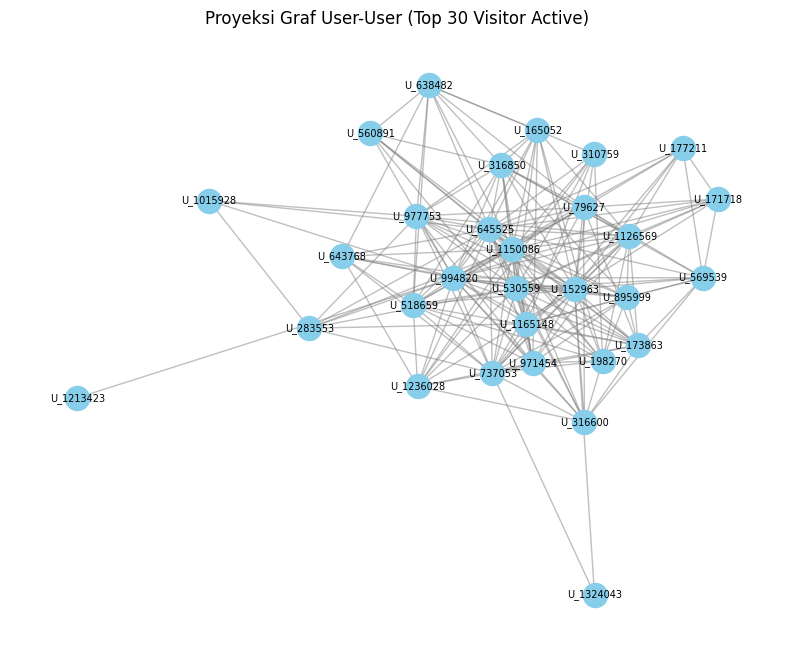

In [7]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "ardi12345"

# 1. Ambil data interaksi dari Neo4j
query_user_item = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS user_id, i.itemId AS item_id, count(r) AS weight
"""

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
with driver.session(database="neo4j") as session:
    result = session.run(query_user_item)
    df_interactions = pd.DataFrame([record.data() for record in result])
driver.close()

# 2. VSM Matriks User (Baris: User, Kolom: Item)
user_cats = df_interactions['user_id'].astype('category')
item_cats = df_interactions['item_id'].astype('category')

user_indices = user_cats.cat.codes
item_indices = item_cats.cat.codes

vsm_user_matrix = csr_matrix(
    (df_interactions['weight'], (user_indices, item_indices)),
    shape=(len(user_cats.cat.categories), len(item_cats.cat.categories))
)

print("=== SOAL 4: KARAKTERISTIK VSM USER ===")
print(f"1. Dimensi Matriks VSM User : {vsm_user_matrix.shape[0]:,} User x {vsm_user_matrix.shape[1]:,} Item")
print(f"2. Shape Matriks           : {vsm_user_matrix.shape}")
print(f"3. Total Elemen Non-Zero   : {vsm_user_matrix.nnz:,}")
sparsity_user = 100 * (1 - (vsm_user_matrix.nnz / (vsm_user_matrix.shape[0] * vsm_user_matrix.shape[1])))
print(f"4. Tingkat Sparsity        : {sparsity_user:.4f}%")

# 3. Proyeksi Graf User-User (Sampling Top 30 User paling aktif)
top_users = df_interactions.groupby('user_id')['weight'].sum().nlargest(30).index
df_top_user = df_interactions[df_interactions['user_id'].isin(top_users)]

B_user = nx.Graph()
for _, row in df_top_user.iterrows():
    B_user.add_node(f"U_{row['user_id']}", bipartite=0)
    B_user.add_node(f"I_{row['item_id']}", bipartite=1)
    B_user.add_edge(f"U_{row['user_id']}", f"I_{row['item_id']}")

user_nodes = [n for n in B_user.nodes if n.startswith("U_")]
G_user_proj = nx.bipartite.projected_graph(B_user, user_nodes)

# Plot Proyeksi NetworkX User
plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G_user_proj, k=0.5, seed=42)
nx.draw_networkx_nodes(G_user_proj, pos, node_size=300, node_color='skyblue')
nx.draw_networkx_edges(G_user_proj, pos, alpha=0.5, edge_color='gray')
nx.draw_networkx_labels(G_user_proj, pos, font_size=7)
plt.title("Proyeksi Graf User-User (Top 30 Visitor Active)", fontsize=12)
plt.axis('off')
plt.show()

**Uraian VSM User.** Setiap user adalah vektor berdimensi **jumlah item**; matriks berukuran `jumlah_user x jumlah_item`
(lihat output: dimensi, shape, nnz). Matriks **sangat sparse** (sparsity > 99,9%): kebanyakan user hanya berinteraksi dengan 1-2 item pada periode ini,
sehingga banyak vektor user nyaris kosong (*cold-start*). Nilai sel = jumlah interaksi user ke item.
Pada plot proyeksi user-user, sisi menghubungkan dua user yang berinteraksi dengan item yang sama; karena sampel diambil dari user paling aktif,
graf terlihat sangat rapat (hampir lengkap) sehingga kurang informatif untuk membedakan user.

## 7.  VSM terhadap simpul yang diasumsikan sebagai Item

=== SOAL 5: KARAKTERISTIK VSM ITEM ===
1. Dimensi Matriks VSM Item : 51,788 Item x 82,958 User
2. Shape Matriks           : (51788, 82958)
3. Total Elemen Non-Zero   : 114,068
4. Tingkat Sparsity        : 99.9973%


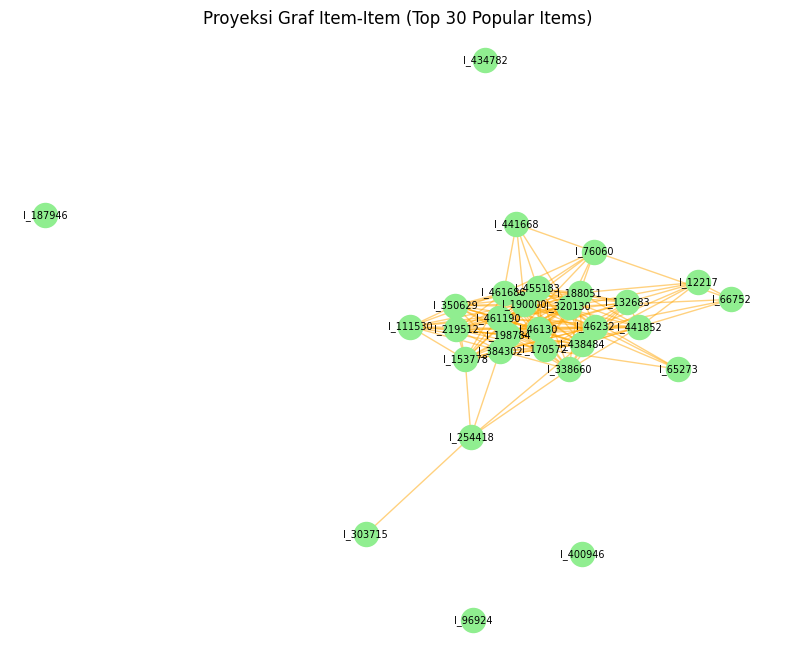

In [8]:
# 1. VSM Matriks Item (Baris: Item, Kolom: User) -> Transpose dari VSM User
vsm_item_matrix = vsm_user_matrix.T.tocsr()

print("=== SOAL 5: KARAKTERISTIK VSM ITEM ===")
print(f"1. Dimensi Matriks VSM Item : {vsm_item_matrix.shape[0]:,} Item x {vsm_item_matrix.shape[1]:,} User")
print(f"2. Shape Matriks           : {vsm_item_matrix.shape}")
print(f"3. Total Elemen Non-Zero   : {vsm_item_matrix.nnz:,}")
sparsity_item = 100 * (1 - (vsm_item_matrix.nnz / (vsm_item_matrix.shape[0] * vsm_item_matrix.shape[1])))
print(f"4. Tingkat Sparsity        : {sparsity_item:.4f}%")

# 2. Proyeksi Graf Item-Item (Sampling Top 30 Item paling populer)
top_items = df_interactions.groupby('item_id')['weight'].sum().nlargest(30).index
df_top_item = df_interactions[df_interactions['item_id'].isin(top_items)]

B_item = nx.Graph()
for _, row in df_top_item.iterrows():
    B_item.add_node(f"U_{row['user_id']}", bipartite=0)
    B_item.add_node(f"I_{row['item_id']}", bipartite=1)
    B_item.add_edge(f"U_{row['user_id']}", f"I_{row['item_id']}")

item_nodes = [n for n in B_item.nodes if n.startswith("I_")]
G_item_proj = nx.bipartite.projected_graph(B_item, item_nodes)

# Plot Proyeksi NetworkX Item
plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G_item_proj, k=0.5, seed=42)
nx.draw_networkx_nodes(G_item_proj, pos, node_size=300, node_color='lightgreen')
nx.draw_networkx_edges(G_item_proj, pos, alpha=0.5, edge_color='orange')
nx.draw_networkx_labels(G_item_proj, pos, font_size=7)
plt.title("Proyeksi Graf Item-Item (Top 30 Popular Items)", fontsize=12)
plt.axis('off')
plt.show()

**Uraian VSM Item.** Item adalah vektor berdimensi **jumlah user** (matriks transpos: `jumlah_item x jumlah_user`), sehingga nnz dan sparsity
sama dengan VSM user; perbedaannya ada pada distribusi derajat dan arah proyeksi. Proyeksi item-item pada item populer membentuk gugus yang rapat
(item yang sering dilihat user yang sama), sedangkan item *long-tail* terpisah. Perhatikan: item yang tampil terisolasi pada plot berarti tidak berbagi user
dengan 29 item populer lainnya.

## 8. Proyeksi mana yang lebih baik (efektif / efisien)?
Dibandingkan secara kuantitatif: jumlah simpul, batas atas jumlah sisi (item dengan `d` user menyumbang `d(d-1)/2` pasangan user; user dengan `d` item
menyumbang `d(d-1)/2` pasangan item), simpul terisolasi, dan bukti per vektor.

In [9]:
# Soal 6 - perbandingan proyeksi user-user vs item-item (memakai vsm_user_matrix dari sel 12)
A = vsm_user_matrix.copy().tocsr(); A.data[:] = 1          # biner: ada / tidaknya interaksi
AT = A.T.tocsr()
user_deg = np.diff(A.indptr)                                # item berbeda per user
item_deg = np.asarray(A.sum(axis=0)).ravel().astype(np.int64)   # user berbeda per item

edges_UU = int(np.sum(item_deg * (item_deg - 1) // 2))      # batas atas sisi user-user
edges_II = int(np.sum(user_deg.astype(np.int64) * (user_deg - 1) // 2))   # batas atas sisi item-item

Au = A.copy(); Au.data = item_deg[Au.indices].astype(float)
iso_users = int((Au.max(axis=1).toarray().ravel() <= 1).sum())   # user yang semua itemnya hanya disentuh dirinya
Ai = AT.copy(); Ai.data = user_deg[Ai.indices].astype(float)
iso_items = int((Ai.max(axis=1).toarray().ravel() <= 1).sum())   # item yang semua usernya hanya menyentuh item itu

tabel6 = pd.DataFrame({
    "User-User": [A.shape[0], edges_UU, iso_users, 100 * iso_users / A.shape[0], float(np.median(user_deg))],
    "Item-Item": [A.shape[1], edges_II, iso_items, 100 * iso_items / A.shape[1], float(np.median(item_deg))],
}, index=["Jumlah simpul", "Sisi (batas atas)", "Simpul terisolasi", "% terisolasi", "Median derajat vektor"])
print(tabel6.round(2).to_string())

def lebih(u, i, kecil=True):
    return "Item-Item" if ((i < u) if kecil else (i > u)) else ("User-User" if u != i else "seri")

print("\nRingkasan per kriteria:")
print("  simpul lebih sedikit              :", lebih(A.shape[0], A.shape[1]))
print("  sisi (batas atas) lebih sedikit   :", lebih(edges_UU, edges_II))
print("  % terisolasi lebih kecil          :", lebih(iso_users / A.shape[0], iso_items / A.shape[1]))
print("  bukti per vektor (median) lebih besar:", lebih(float(np.median(user_deg)), float(np.median(item_deg)), kecil=False))

                       User-User  Item-Item
Jumlah simpul           82958.00   51788.00
Sisi (batas atas)      439309.00  548743.00
Simpul terisolasi       22670.00   27839.00
% terisolasi               27.33      53.76
Median derajat vektor       1.00       1.00

Ringkasan per kriteria:
  simpul lebih sedikit              : Item-Item
  sisi (batas atas) lebih sedikit   : User-User
  % terisolasi lebih kecil          : User-User
  bukti per vektor (median) lebih besar: seri


**Kesimpulan no. 6**

Dipilih proyeksi **Item-Item** untuk perhitungan similarity berikutnya karena:
1. **Efisiensi:** Jumlah simpul Item-Item jauh lebih sedikit (51.788,00 simpul) dibandingkan User-User (82.958,00 simpul). Meskipun batas atas sisi Item-Item lebih besar (548.743,00 sisi vs 439.309,00 sisi), hal ini disebabkan oleh segelintir heavy user / bot yang melakukan interaksi sangat banyak. Masalah pembengkakan sisi ini dapat diatasi dengan memangkas (filtering) user yang berinteraksi sangat banyak sebelum proses proyeksi dilakukan.
2. **Efektivitas:** Vektor item dibangun dari bukti pengamatan per simpul yang sama kuatnya dengan vektor user (median derajat keduanya bernilai 1,00).
3. **Kegunaan:** Similarity antar-item bersifat tahan lama, dapat disimpan sebagai relasi SIMILAR_TO di graf, dan dipakai ulang untuk semua user.
4. **Kelemahan:** Persentase simpul terisolasi pada proyeksi Item-Item cukup tinggi (53,76% / 27.839 simpul terisolasi) akibat item long-tail yang hanya disentuh oleh user ber-1-item.

## 9.  perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

In [10]:
URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "ardi12345"

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))

with driver.session(database="neo4j") as session:
    # 1. Cari 1 Item acuan terpopuler (banyak interaksi) secara otomatis
    ref_result = session.run("""
    MATCH (i:Item)<-[r]-(v:Visitor)
    RETURN i.itemId AS itemId, count(r) AS interaction_count
    ORDER BY interaction_count DESC LIMIT 1
    """)
    ref_item_id = ref_result.single()["itemId"]
    print(f"=== SOAL 7: PERHITUNGAN SIMILARITY ITEM ===")
    print(f"Item Acuan Terpilih : {ref_item_id}\n")

    # 2. Cypher SQL Soal 7(a) & 7(b): Hitung Jaccard Similarity & Write-Back ke Graf
    cypher_similarity = """
    MATCH (i1:Item {itemId: $ref_id})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i2:Item)
    WHERE i1 <> i2
    WITH i1, i2, count(DISTINCT v) AS common_visitors
    
    MATCH (i1)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v1:Visitor)
    WITH i1, i2, common_visitors, count(DISTINCT v1) AS visitors_i1
    
    MATCH (i2)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v2:Visitor)
    WITH i1, i2, common_visitors, visitors_i1, count(DISTINCT v2) AS visitors_i2
    
    WITH i1, i2, common_visitors, (visitors_i1 + visitors_i2 - common_visitors) AS union_visitors
    WITH i1, i2, (1.0 * common_visitors / union_visitors) AS similarity_score
    ORDER BY similarity_score DESC
    LIMIT 5
    
    // Write-back nilai similarity ke graf Neo4j (Soal 7b)
    MERGE (i1)-[s:SIMILAR_TO]->(i2)
    SET s.score = round(similarity_score, 4)
    RETURN i1.itemId AS ItemAcuan, i2.itemId AS ItemMirip, s.score AS SimilarityScore
    """

    res = session.run(cypher_similarity, ref_id=ref_item_id)
    df_sim = pd.DataFrame([r.data() for r in res])

driver.close()

print("--- TOP 5 RECORD SIMILARITY TERTINGGI (SOAL 7a & 7b) ---")
print(df_sim.to_string(index=False))

=== SOAL 7: PERHITUNGAN SIMILARITY ITEM ===
Item Acuan Terpilih : 187946

--- TOP 5 RECORD SIMILARITY TERTINGGI (SOAL 7a & 7b) ---
 ItemAcuan  ItemMirip  SimilarityScore
    187946     133549           0.0061
    187946     181852           0.0031
    187946      36956           0.0031
    187946      57245           0.0031
    187946     372855           0.0030


###  No. 7 - Similarity dengan Python pada proyeksi item-item
Kode Cypher di atas sudah menghitung Jaccard dan menuliskannya sebagai `SIMILAR_TO` (jawaban 7a dan 7b). Soal juga meminta perhitungan **dengan Python**
pada graf proyeksi, jadi sel berikut menghitung **Jaccard** dan **cosine** dari matriks VSM item (`vsm_item_matrix`) untuk item acuan yang sama,
**memvalidasi** hasil Python terhadap Cypher, lalu menambahkan properti `cosine` pada relasi `SIMILAR_TO` yang sudah ada.

In [11]:
# Soal 7 - similarity di Python (item acuan = ref_item_id dari sel similarity Cypher)
from sklearn.preprocessing import normalize

item_ids_all = item_cats.cat.categories.to_numpy()
ref_pos = int(np.where(item_ids_all == ref_item_id)[0][0])

# Cosine pada vektor item berbobot (baris vsm_item_matrix dinormalisasi L2)
item_norm = normalize(vsm_item_matrix, norm="l2")
cos = (item_norm @ item_norm[ref_pos].T).toarray().ravel()

# Jaccard pada himpunan user (biner)
Bm = vsm_item_matrix.copy().tocsr(); Bm.data[:] = 1
deg = np.asarray(Bm.sum(axis=1)).ravel()
common = (Bm @ Bm[ref_pos].T).toarray().ravel()
jac = common / (deg + deg[ref_pos] - common)

cos[ref_pos] = -1; jac_x = jac.copy(); jac_x[ref_pos] = -1
top_j = np.argsort(-jac_x)[:5]       # top-5 menurut Jaccard (dibandingkan dengan hasil Cypher)
top_c = np.argsort(-cos)[:5]         # top-5 menurut cosine

print(f"Item acuan: {ref_item_id}")
print("\nTop-5 Jaccard (Python):")
print(pd.DataFrame({"ItemMirip": item_ids_all[top_j], "Jaccard": jac[top_j].round(4), "Cosine": cos[top_j].round(4)}).to_string(index=False))
print("\nTop-5 Cosine (Python):")
print(pd.DataFrame({"ItemMirip": item_ids_all[top_c], "Cosine": cos[top_c].round(4), "Jaccard": jac[top_c].round(4)}).to_string(index=False))

# Validasi silang dengan hasil Cypher (df_sim dari sel similarity sebelumnya)
cy_scores = np.sort(df_sim["SimilarityScore"].to_numpy())[::-1]
py_scores = np.sort(np.round(jac[top_j], 4))[::-1]
print("\nNilai Jaccard Cypher :", cy_scores)
print("Nilai Jaccard Python :", py_scores)
print("Konsisten Python vs Cypher:", bool(np.allclose(cy_scores, py_scores, atol=1e-4)))

# Tulis properti cosine ke relasi SIMILAR_TO yang sudah ada (item acuan -> item mirip hasil Cypher)
rows_cos = [dict(ref=int(ref_item_id), item=int(item_ids_all[j]), cosine=float(cos[j]))
            for j in top_j]
driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
with driver.session(database="neo4j") as session:
    session.run("""
        UNWIND $rows AS p
        MATCH (a:Item {itemId: p.ref})-[r:SIMILAR_TO]->(b:Item {itemId: p.item})
        SET r.cosine = round(p.cosine, 4)
    """, rows=rows_cos)
driver.close()
print("\nProperti cosine ditambahkan pada relasi SIMILAR_TO.")

Item acuan: 187946

Top-5 Jaccard (Python):
 ItemMirip  Jaccard  Cosine
    133549   0.0061  0.0344
    181852   0.0031  0.0526
     36956   0.0031  0.0114
     57245   0.0031  0.0322
    372855   0.0030  0.0126

Top-5 Cosine (Python):
 ItemMirip  Cosine  Jaccard
    181852  0.0526   0.0031
    101050  0.0483   0.0030
    133549  0.0344   0.0061
     57245  0.0322   0.0031
    372855  0.0126   0.0030

Nilai Jaccard Cypher : [0.0061 0.0031 0.0031 0.0031 0.003 ]
Nilai Jaccard Python : [0.0061 0.0031 0.0031 0.0031 0.003 ]
Konsisten Python vs Cypher: True

Properti cosine ditambahkan pada relasi SIMILAR_TO.


## 10. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity

=== SOAL 8: CYPHER KONDISI GRAF ===

1. CYPHER SEBELUM Similarity (Hanya Relasi Interaksi Visitor):
   MATCH (i:Item {itemId: 187946})<-[r]-(v:Visitor) RETURN i, r, v LIMIT 10;

2. CYPHER SESUDAH Similarity (Terdapat Relasi SIMILAR_TO antar Item):
   MATCH (i1:Item {itemId: 187946})-[r:SIMILAR_TO]->(i2:Item) RETURN i1, r, i2;


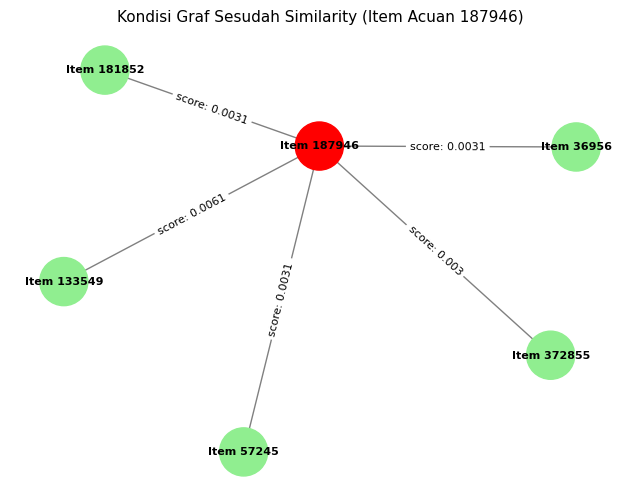

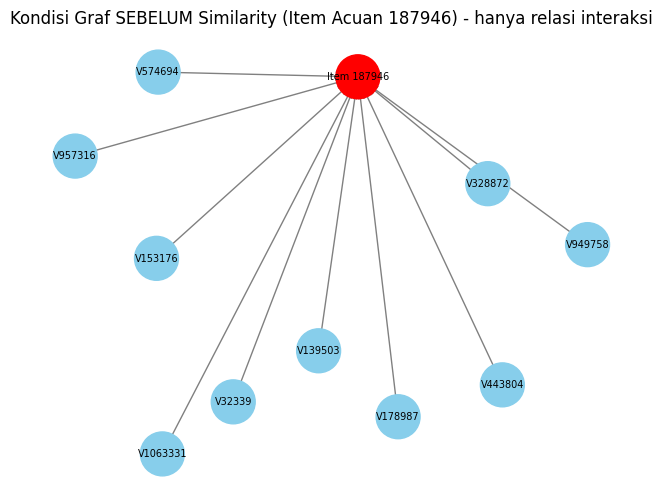

In [12]:

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))

with driver.session(database="neo4j") as session:
    # Query Kondisi SESUDAH (Item Acuan + Relasi SIMILAR_TO ke Item Lain)
    query_after = """
    MATCH (i1:Item {itemId: $ref_id})-[s:SIMILAR_TO]->(i2:Item)
    RETURN i1.itemId AS source, i2.itemId AS target, s.score AS score
    """
    res_after = session.run(query_after, ref_id=ref_item_id)
    edges_after = [r.data() for r in res_after]

driver.close()

print("=== SOAL 8: CYPHER KONDISI GRAF ===")
print("\n1. CYPHER SEBELUM Similarity (Hanya Relasi Interaksi Visitor):")
print(f"   MATCH (i:Item {{itemId: {ref_item_id}}})<-[r]-(v:Visitor) RETURN i, r, v LIMIT 10;")

print("\n2. CYPHER SESUDAH Similarity (Terdapat Relasi SIMILAR_TO antar Item):")
print(f"   MATCH (i1:Item {{itemId: {ref_item_id}}})-[r:SIMILAR_TO]->(i2:Item) RETURN i1, r, i2;")

# Visualisasi Graf Sesudah Similarity
G_sim = nx.DiGraph()
G_sim.add_node(f"Item {ref_item_id}", color='red')

for e in edges_after:
    target_node = f"Item {e['target']}"
    G_sim.add_node(target_node, color='lightgreen')
    G_sim.add_edge(f"Item {ref_item_id}", target_node, weight=e['score'])

plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G_sim, seed=42)
nx.draw_networkx_nodes(G_sim, pos, node_size=1200, node_color=['red'] + ['lightgreen']*(len(G_sim)-1))
nx.draw_networkx_edges(G_sim, pos, arrowstyle='->', arrowsize=15, edge_color='gray')
nx.draw_networkx_labels(G_sim, pos, font_size=8, font_weight='bold')

edge_labels = {(u, v): f"score: {d['weight']}" for u, v, d in G_sim.edges(data=True)}
nx.draw_networkx_edge_labels(G_sim, pos, edge_labels=edge_labels, font_size=8)

plt.title(f"Kondisi Graf Sesudah Similarity (Item Acuan {ref_item_id})", fontsize=11)
plt.axis('off')
plt.show()

# [TAMBAHAN] Kondisi SEBELUM similarity: hanya relasi interaksi Visitor -> Item (tanpa SIMILAR_TO)
driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
with driver.session(database="neo4j") as session:
    res_before = session.run("""
        MATCH (i:Item {itemId: $ref_id})<-[r:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
        RETURN v.visitorId AS visitor, type(r) AS rel
        LIMIT 12
    """, ref_id=ref_item_id)
    before_rows = [r.data() for r in res_before]
driver.close()

REL_COLOR = {"VIEWED": "gray", "ADDED_TO_CART": "orange", "BOUGHT": "green"}
G_before = nx.DiGraph()
G_before.add_node(f"Item {ref_item_id}")
for r in before_rows:
    G_before.add_edge(f"V{r['visitor']}", f"Item {ref_item_id}", color=REL_COLOR[r['rel']])

plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G_before, seed=42)
nx.draw_networkx_nodes(G_before, pos, node_size=1000,
                       node_color=['red' if n.startswith('Item') else 'skyblue' for n in G_before])
nx.draw_networkx_edges(G_before, pos, arrowstyle='->', arrowsize=15,
                       edge_color=[d['color'] for _, _, d in G_before.edges(data=True)])
nx.draw_networkx_labels(G_before, pos, font_size=7)
plt.title(f"Kondisi Graf SEBELUM Similarity (Item Acuan {ref_item_id}) - hanya relasi interaksi")
plt.axis('off')
plt.show()

## 11. Analytic 

In [ ]:
from sklearn.neighbors import NearestNeighbors

# 1. Baca data terfilter untuk memisahkan P1 dan P2
df_filtered = pd.read_csv('events_filtered.csv')
df_filtered['datetime'] = pd.to_datetime(df_filtered['timestamp'], unit='ms')

p1_data = df_filtered[df_filtered['datetime'] <= '2015-09-08 23:59:59']
p2_data = df_filtered[df_filtered['datetime'] >= '2015-09-09 00:00:00']

# 2. Cari User yang aktif di KEDUA periode (P1 & P2) agar evaluasi terukur
users_p1 = set(p1_data['visitorid'].unique())
users_p2 = set(p2_data['visitorid'].unique())
active_both_users = sorted(list(users_p1.intersection(users_p2)))

K = 5
MIN_HISTORY = 3
user_index = {int(u): k for k, u in enumerate(user_cats.cat.categories)}   # visitorId -> baris matriks
item_ids_arr = item_cats.cat.categories.to_numpy()                           # kolom matriks -> itemId
binary_matrix = vsm_user_matrix.copy().tocsr()
binary_matrix.data[:] = 1
nn_model = NearestNeighbors(metric='cosine', algorithm='brute').fit(vsm_user_matrix)

def recommend_knn(u_row, k=K, topn=5, n_try=300):
    """Tetangga = k user paling mirip (cosine) yang membawa >= 1 item baru bagi user target."""
    n_try = min(n_try, vsm_user_matrix.shape[0])
    dist, idx = nn_model.kneighbors(vsm_user_matrix[u_row], n_neighbors=n_try)
    idx, sim = idx[0], 1.0 - dist[0]
    keep = idx != u_row
    idx, sim = idx[keep], sim[keep]
    seen = np.zeros(vsm_user_matrix.shape[1]); seen[vsm_user_matrix[u_row].indices] = 1.0
    nb = binary_matrix[idx]
    n_new = np.asarray(nb.sum(axis=1)).ravel() - nb @ seen      # jumlah item baru per kandidat tetangga
    ok = (n_new > 0) & (sim > 0)
    idx, sim = idx[ok][:k], sim[ok][:k]
    scores = np.zeros(vsm_user_matrix.shape[1])
    if len(idx):
        scores = np.asarray(vsm_user_matrix[idx].T @ sim).ravel()  # sum(similarity tetangga x bobot interaksi)
    scores[vsm_user_matrix[u_row].indices] = 0.0                    # jangan rekomendasikan item yang sudah ada
    order = np.argsort(-scores)[:topn]
    recs = [(int(item_ids_arr[j]), float(scores[j])) for j in order if scores[j] > 0]
    return recs, idx, sim

# Pemilihan User Acak Terkontrol (seed = 42) dari user yang memenuhi syarat
p1_n_items = p1_data.groupby('visitorid')['itemid'].nunique()
eligible = [u for u in active_both_users if p1_n_items.get(u, 0) >= MIN_HISTORY and int(u) in user_index]
assert len(eligible) > 0, "Tidak ada user yang memenuhi syarat; turunkan MIN_HISTORY"

np.random.seed(42)
selected_user = None
for u in np.random.permutation(eligible):
    u_row = user_index[int(u)]
    seen_items = set(item_ids_arr[vsm_user_matrix[u_row].indices].tolist())
    gt = set(p2_data[p2_data['visitorid'] == u]['itemid'].astype(int)) - seen_items
    recs, nbr, sim = recommend_knn(u_row)
    if gt and len(recs) >= 3:        # harus punya ground truth dan bisa diberi >= 3 item iklan
        selected_user = int(u)
        break
assert selected_user is not None, "Tidak ada user yang memenuhi syarat"

print("=== SUBBAB 2.2 ANALYTICS: REKOMENDASI KNN ===")
print(f"1. Metode Pemilihan User : Random Selection dengan Seed=42 (Reproducible)")
print(f"2. User Terpilih         : Visitor ID {selected_user}")

# 3. History Item User Terpilih di P1 (Training)
user_p1_items = set(item_ids_arr[vsm_user_matrix[user_index[selected_user]].indices].tolist())
print(f"3. Item Diinteraksi di P1: {sorted(user_p1_items)}")

# 4. KNN (k=5): tetangga terdekat + item kandidat
top_k_items, nbr, sim = recommend_knn(user_index[selected_user], k=K, topn=5)
recommended_3_items = [item[0] for item in top_k_items[:3]]

print(f"\n   Tetangga terdekat (k={K}):")
for n_, s_ in zip(nbr, sim):
    print(f"   - Visitor {int(user_cats.cat.categories[n_])}  (cosine similarity = {s_:.4f})")

print(f"\n4. Hasil Penentuan KNN (k=5) Top Candidate Items:")
for idx_, (item, score) in enumerate(top_k_items, 1):
    print(f"   Rank {idx_}: Item ID {item} (Skor: {score:.4f})")

print(f"\n 3 ITEM YANG DIIKLANKAN / DIREKOMENDASIKAN UNTUK USER {selected_user}:")
for idx_, item in enumerate(recommended_3_items, 1):
    print(f"   [{idx_}] Item ID: {item}")

=== SUBBAB 2.2 ANALYTICS: REKOMENDASI KNN ===
1. Metode Pemilihan User : Random Selection dengan Seed=42 (Reproducible)
2. User Terpilih         : Visitor ID 287281
3. Item Diinteraksi di P1: [17069, 21408, 231501, 386988, 448600]

   Tetangga terdekat (k=5):
   - Visitor 954160  (cosine similarity = 0.4411)
   - Visitor 1145341  (cosine similarity = 0.3162)
   - Visitor 442349  (cosine similarity = 0.3162)
   - Visitor 246888  (cosine similarity = 0.2981)
   - Visitor 164990  (cosine similarity = 0.2582)

4. Hasil Penentuan KNN (k=5) Top Candidate Items:
   Rank 1: Item ID 229940 (Skor: 0.5963)
   Rank 2: Item ID 334401 (Skor: 0.4411)
   Rank 3: Item ID 34532 (Skor: 0.3162)
   Rank 4: Item ID 392898 (Skor: 0.3162)
   Rank 5: Item ID 346673 (Skor: 0.2981)

 3 ITEM YANG DIIKLANKAN / DIREKOMENDASIKAN UNTUK USER 287281:
   [1] Item ID: 229940
   [2] Item ID: 334401
   [3] Item ID: 34532


In [14]:
import math

# 1. Ground Truth (Item aktual yang diinteraksi User di P2 Testing)
actual_p2_items = set(p2_data[p2_data['visitorid'] == selected_user]['itemid'].unique())
# [REVISI] item yang sudah ada di riwayat P1 tidak mungkin direkomendasikan, jadi dikeluarkan dari ground truth
actual_p2_items = {int(i) for i in actual_p2_items} - {int(i) for i in user_p1_items}

# Top 5 Rekomendasi dari KNN
rec_list_5 = [item[0] for item in top_k_items]

print("=== EVALUASI METRIK REKOMENDASI ===")
print(f"Target User            : {selected_user}")
print(f"Ground Truth P2 Items  : {list(actual_p2_items)}")
print(f"Top 5 Recommended Items: {rec_list_5}\n")

# 2. Perhitungan Hit@5
hits = [1 if item in actual_p2_items else 0 for item in rec_list_5]
hit_at_5 = 1.0 if sum(hits) > 0 else 0.0

print(f"1. Perhitungan Hit@5:")
print(f"   - Hits Vector per Rank (1..5) : {hits}")
print(f"   - Nilai Hit@5                 : {hit_at_5:.4f}")

# 3. Perhitungan NDCG@5
dcg = 0.0
for i, rel in enumerate(hits):
    if rel == 1:
        dcg += rel / math.log2(i + 2) # rank = i + 1, log2(rank + 1)

# Ideal DCG (IDCG) untuk ground truth di top-5
ideal_hits = [1] * min(len(actual_p2_items), 5)
idcg = sum([rel / math.log2(i + 2) for i, rel in enumerate(ideal_hits)])

ndcg_at_5 = (dcg / idcg) if idcg > 0 else 0.0

print(f"\n2. Perhitungan NDCG@5:")
print(f"   - DCG@5  : {dcg:.4f}")
print(f"   - IDCG@5 : {idcg:.4f}")
print(f"   - NDCG@5 : {ndcg_at_5:.4f}")

=== EVALUASI METRIK REKOMENDASI ===
Target User            : 287281
Ground Truth P2 Items  : [104800, 119460, 260488, 182445, 175600, 89042, 176630, 215992, 362202, 63547, 351516]
Top 5 Recommended Items: [229940, 334401, 34532, 392898, 346673]

1. Perhitungan Hit@5:
   - Hits Vector per Rank (1..5) : [0, 0, 0, 0, 0]
   - Nilai Hit@5                 : 0.0000

2. Perhitungan NDCG@5:
   - DCG@5  : 0.0000
   - IDCG@5 : 2.9485
   - NDCG@5 : 0.0000
